# Blazar Classification

## 1. Importe de librerias

In [145]:
from astropy.io import fits
from astropy.table import Table
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

## 2. Carga de datos y conversión del archivo .FITS

In [ ]:
hdul = fits.open("data/raw/gll_psc_v35.fit")
astropy_table = Table.read(hdul[1]) #El índice 1 contiene la tabla de datos

In [147]:
#Cambia el orden de bytes de los datos a nativo si es necesario
def _to_native_byteorder(arr: np.ndarray) -> np.ndarray:
    if arr.dtype.byteorder not in ("=", "|"):
        arr = arr.byteswap().view(arr.dtype.newbyteorder("="))
    return arr

#Convierte la tabla FITS a un DataFrame de Pandas, expandiendo las columnas multidimensionales en columnas separadas
def fits_table_to_full_dataframe(astropy_table: Table) -> pd.DataFrame:
    scalar_cols = []
    multidim_cols = []

    for name in astropy_table.colnames:
        col = astropy_table[name]

        if len(col.shape) <= 1:
            scalar_cols.append(name)
        else:
            multidim_cols.append(name)

    for name in astropy_table.colnames:
        data = np.asarray(astropy_table[name])
        if data.dtype.kind in "fiu":  # float, int, unsigned int
            astropy_table[name] = _to_native_byteorder(data)

    df = astropy_table[scalar_cols].to_pandas()

    for col in df.columns:
        if df[col].dtype == object and len(df) > 0 and isinstance(df[col].iloc[0], bytes):
            df[col] = df[col].str.decode("utf-8")

    expanded = {}
    for name in multidim_cols:
        arr = np.asarray(astropy_table[name])  # shape (n_rows, k [, ...])
        arr = arr.reshape(len(arr), -1)        # flatten any extra dims to 2D
        n_sub = arr.shape[1]
        for i in range(n_sub):
            expanded[f"{name}_{i}"] = arr[:, i]

    if expanded:
        df = pd.concat([df, pd.DataFrame(expanded, index=df.index)], axis=1)

    return df, multidim_cols, scalar_cols

## 3. Análisis exploratorio del dataset

## 3.1 Identificación de columnas con valores NaN y eliminación de columnas no relevantes

In [148]:
#Cuenta el número de valores vacíos en cada columna del DataFrame
def contar_vacios(df):
    conteo = df.isnull().sum()
    for col in df.select_dtypes(include='object').columns:
        vacios_texto = df[col].astype(str).str.strip().eq('').sum()
        conteo[col] = conteo[col] + vacios_texto
    return conteo.sort_values(ascending=False)

In [149]:
df, m_cols, s_cols = fits_table_to_full_dataframe(astropy_table)

In [150]:
def drop_columns(df, prefix):
    columns_to_drop = [col for col in df.columns if col.startswith(prefix)]
    df = df.drop(columns=columns_to_drop)
    return df

df = df.copy()
df = df.drop(columns=[
    "DataRelease",
    "RAJ2000",
    "DEJ2000",
    "GLON",
    "ROI_num",
    "Extended_Source_Name",
    "Flags",
    "Source_Name",
    "DEC_Counterpart",
    "RA_Counterpart",
    "CLASS2",#La dropee, pero hay 200 datos catalogados con solo esta clase, se puede retomar
    "PLEC_EPeak" #Columna inferible con otras variables conocidas, y que induce muchos NaN
])

df = drop_columns(df, "Conf_68")
df = drop_columns(df, "Conf_95")
df = drop_columns(df, "ASSOC")
df = drop_columns(df, "Unc")
df

,GLAT,Signif_Avg,Pivot_Energy,Flux1000,Energy_Flux100,SpectrumType,PL_Flux_Density,PL_Index,LP_Flux_Density,LP_Index,...,Sqrt_TS_History_4,Sqrt_TS_History_5,Sqrt_TS_History_6,Sqrt_TS_History_7,Sqrt_TS_History_8,Sqrt_TS_History_9,Sqrt_TS_History_10,Sqrt_TS_History_11,Sqrt_TS_History_12,Sqrt_TS_History_13
0,-42.729538,8.492646,1917.715454,1.479606e-10,1.735209e-12,PowerLaw,4.284426e-14,2.247396,4.841716e-14,2.128013,...,2.024323,3.840539,3.172182,3.046058,0.000000,0.410956,1.517305,1.970749,2.060067,2.413337
1,-53.029457,5.681097,1379.882935,1.554103e-10,1.930614e-12,PowerLaw,9.782522e-14,2.330765,1.144858e-13,2.246985,...,1.580514,1.751642,2.230891,2.674823,4.963608,0.000000,0.811790,0.000000,2.932223,1.202639
2,-35.959175,4.197268,5989.263184,6.779151e-11,8.050527e-13,PowerLaw,2.134281e-15,1.856152,3.026530e-15,1.801879,...,1.231121,0.000000,1.708250,1.292136,0.464855,0.000000,1.811485,0.000000,0.000000,0.990755
3,-14.338059,5.523873,3218.100098,1.215529e-10,1.369124e-12,PowerLaw,1.136274e-14,2.155106,1.238304e-14,2.114229,...,0.000000,0.285321,1.893470,0.960601,2.011504,0.000000,0.062681,2.254160,3.200194,0.000000
4,-67.305008,24.497219,2065.146729,7.024454e-10,7.807578e-12,PowerLaw,1.690367e-13,2.081634,1.778363e-13,2.052470,...,7.208447,5.825856,6.605715,6.771310,10.708491,5.548215,4.809200,3.607690,6.028563,3.113805
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7190,-76.542862,18.289204,2930.842285,3.582566e-10,4.093997e-12,PowerLaw,4.240267e-14,1.928476,4.283416e-14,1.924309,...,5.292601,3.387712,3.265998,5.800932,5.238139,3.208765,5.406776,6.468659,4.950607,7.029840
7191,-46.256252,7.791155,581.708130,1.702680e-10,2.355763e-12,LogParabola,1.064677e-12,2.638458,1.327379e-12,2.466453,...,1.350941,2.293291,0.000000,3.164715,0.710967,0.480907,2.085095,2.797239,1.989603,1.611573
7192,-64.472755,5.150436,717.048584,7.982052e-11,1.116031e-12,LogParabola,2.954065e-13,2.714450,4.606104e-13,2.639918,...,1.267902,1.320493,0.182238,2.117821,1.572779,0.860041,0.000000,2.521716,1.734976,0.900663
7193,-74.919624,11.475555,1490.850708,2.448128e-10,1.752340e-12,LogParabola,1.005016e-13,2.094933,1.236632e-13,1.904424,...,3.418002,2.101004,3.087870,0.532565,2.358482,1.555077,2.835052,2.814638,3.999843,4.212942


In [151]:
rows, cols = df.shape
vacios = contar_vacios(df)

print("="*60)
print(f"Columnas multidimensionales: {len(m_cols)}")
print(f"Columnas unidimensionales: {len(s_cols)}")

print("="*60)
print(f"Columnas con valores nulos/vacios: ")
for col, count in vacios.items():
    if count > 0:
      print(f"{col}: {count}")

print("="*60)
print(f"Número de filas: {rows}")
print(f"Número de columnas: {cols}")
print("="*60)
print(f"Cantidad de columnas (Antes de expandir las multidim): {len(astropy_table.columns)}")
print(f"Cantidad de columnas: {len(df.columns)}")

Columnas multidimensionales: 7
Columnas unidimensionales: 72
Columnas con valores nulos/vacios: 
CLASS1: 2423
LP_EPeak: 903
PLEC_Flux_Density: 4
PLEC_ExpfactorS: 4
PLEC_Exp_Index: 4
PLEC_IndexS: 4
LP_Flux_Density: 3
LP_beta: 3
LP_Index: 3
PL_Index: 1
Signif_Avg: 1
PL_Flux_Density: 1
Número de filas: 7195
Número de columnas: 79
Cantidad de columnas (Antes de expandir las multidim): 79
Cantidad de columnas: 79


C:\Users\jonha\AppData\Local\Temp\ipykernel_15620\1922918907.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


## 3.2. Eliminación de registros con pocos NaN para evitar droppear columnas relevantes

In [152]:
#Expandir el tipo de espectro con OhE
df = pd.get_dummies(df, columns=["SpectrumType"], dtype=int)

In [153]:
cols = ["PLEC_IndexS", "PLEC_ExpfactorS", "PLEC_Exp_Index", "PLEC_Flux_Density",
        "LP_beta", "LP_Index", "LP_Flux_Density", "PL_Index", "PL_Flux_Density", "Signif_Avg"]  

df = df.dropna(subset=cols)   
df.shape

(7191, 81)

In [154]:
df= df.drop(df[df["CLASS1"].str.strip() == ""].index)
df["CLASS1"] = df["CLASS1"].str.lower()
df["CLASS1"] = df["CLASS1"].str.strip()

df["CLASS1"] = df["CLASS1"].apply(lambda x : x if x in ["bll", "bcu", "fsrq"] else "other")

df["BlazarDist"] = df["CLASS1"].apply(lambda x: 1 if x in ["bll", "bcu", "fsrq"] else 0)
print(df["CLASS1"].value_counts())
print(df["BlazarDist"].value_counts())

CLASS1
bcu      1623
bll      1490
other     836
fsrq      819
Name: count, dtype: int64
BlazarDist
1    3932
0     836
Name: count, dtype: int64


In [155]:
df = df[[
    "CLASS1",
    "BlazarDist",
    "Variability_Index",
    "Frac_Variability",
    "SpectrumType_LogParabola",
    "SpectrumType_PowerLaw",
    "SpectrumType_PLSuperExpCutoff",
    "Energy_Flux100",
    "Flux1000",
    "LP_Index",
    "LP_SigCurv",
    "PL_Index",
    "Pivot_Energy",
    #"Flux_Band_0",
    #"Flux_Band_4",
    #"Flux_Band_6",
    #"Flux_Band_7",
    "nuFnu_Band_0",
    "nuFnu_Band_4",
    "nuFnu_Band_6",
    "nuFnu_Band_7",

    "LP_beta",
    "LP_EPeak",
    "GLAT"
    
    ]]

#NOTA: Si se quiere incluir flux_peak y signif_peak, se tratan como un indicador al contener infinitos
#Si se quiere hacer un modelo físico riguroso, se debería enriquecer, con redshift, v_peak, radio, infrarojo

In [156]:
num = df.select_dtypes("number")
spearman_corr = num.corr(method='spearman')
pearson_corr = num.corr(method='pearson')
diff = spearman_corr - pearson_corr



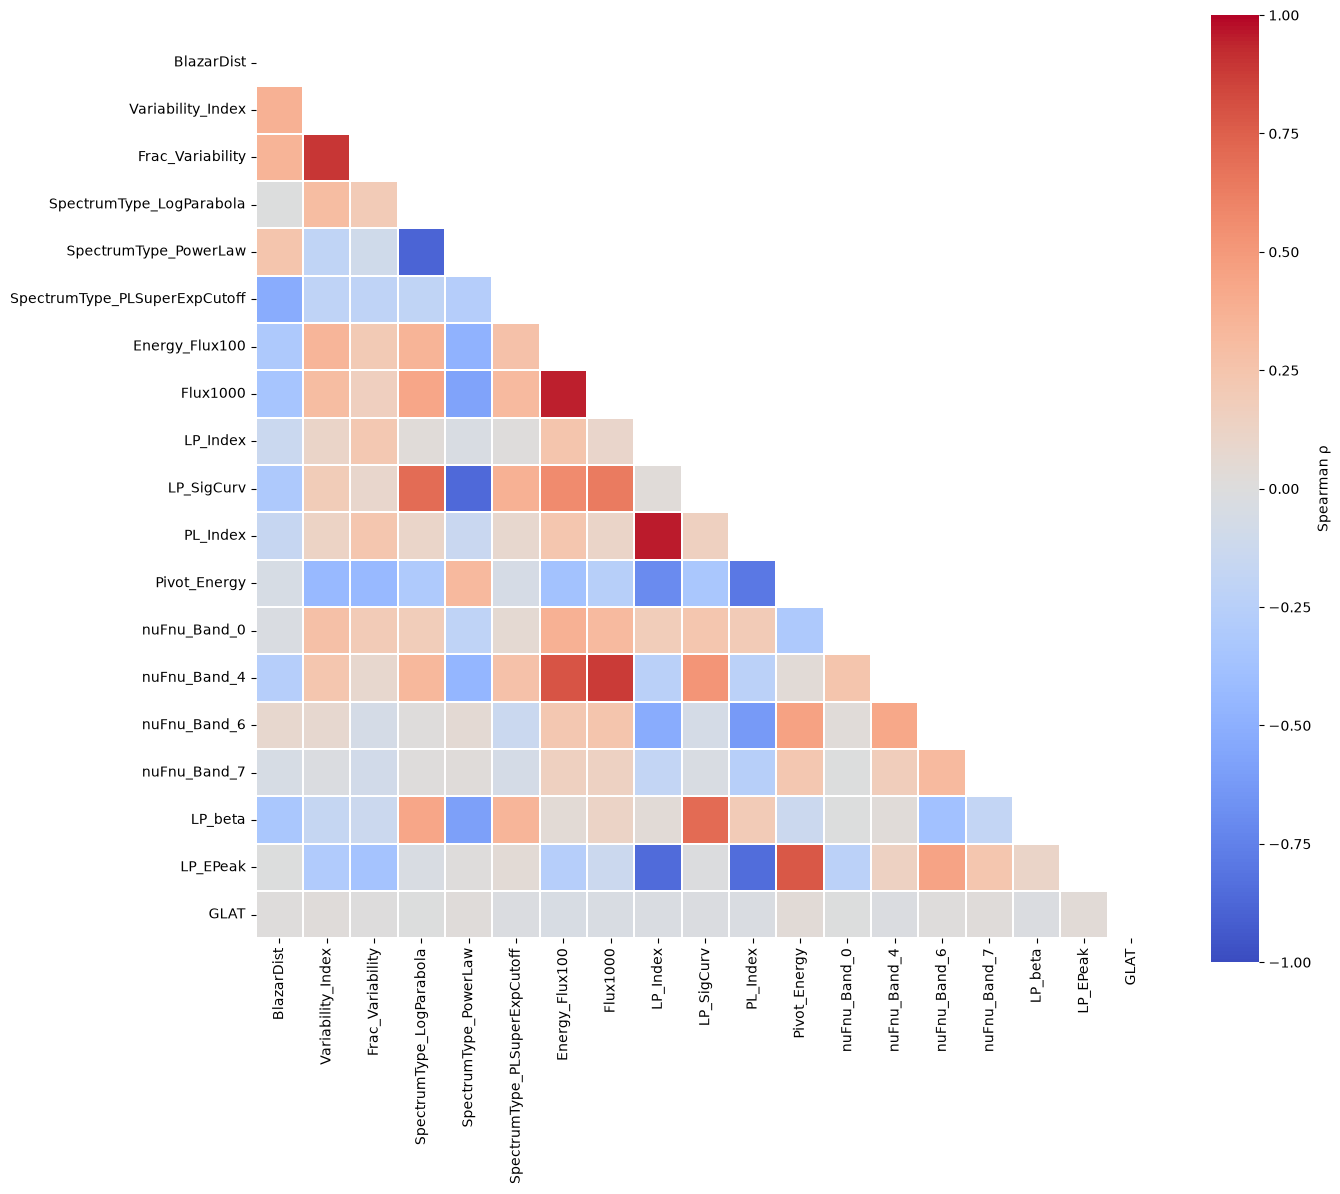

In [157]:
mask = np.triu(np.ones_like(spearman_corr, dtype=bool))
plt.figure(figsize=(14, 12))
sns.heatmap(spearman_corr, mask=mask, cmap="coolwarm", vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.3, cbar_kws={"label": "Spearman ρ"})
plt.tight_layout()
plt.show()

In [158]:
pairs = (spearman_corr.where(np.tril(np.ones(spearman_corr.shape, dtype=bool), k=-1))
             .stack()
             .rename("rho")
             .reset_index()
             .rename(columns={"level_0": "var1", "level_1": "var2"}))
pairs["abs_rho"] = pairs["rho"].abs()
print(pairs[pairs["abs_rho"] > 0.9].sort_values("abs_rho", ascending=False))

         var1            var2       rho   abs_rho
198  PL_Index        LP_Index  0.959161  0.959161
139  Flux1000  Energy_Flux100  0.951872  0.951872


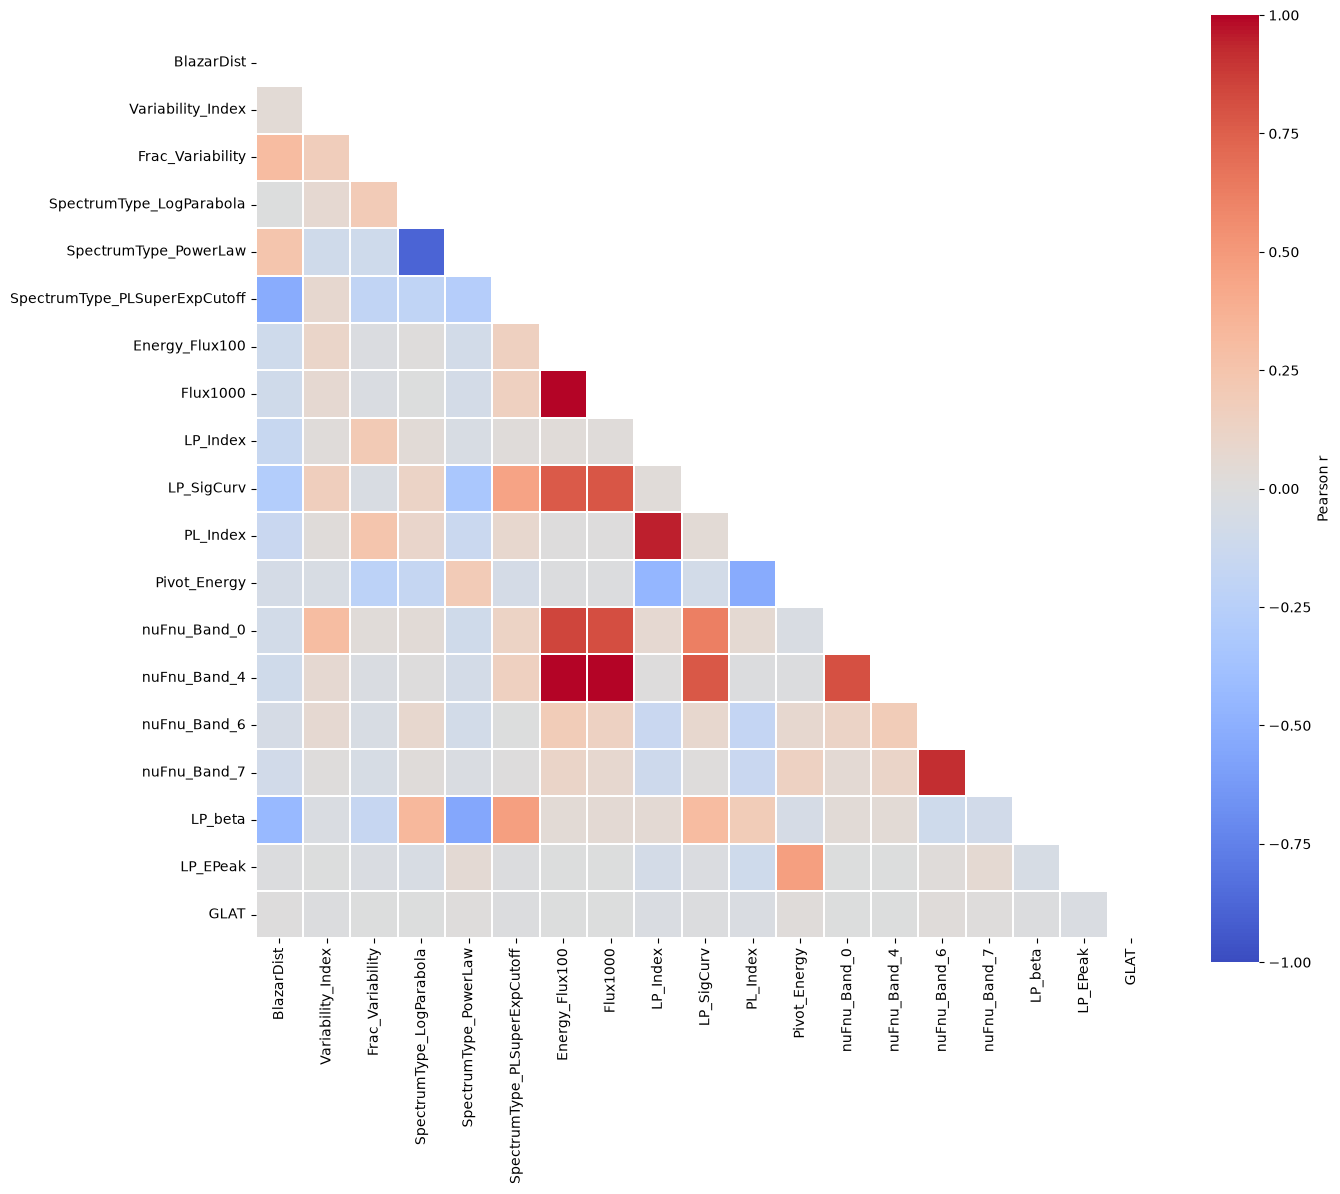

In [159]:
mask = np.triu(np.ones_like(pearson_corr, dtype=bool))
plt.figure(figsize=(14, 12))
sns.heatmap(pearson_corr, mask=mask, cmap="coolwarm", vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.3, cbar_kws={"label": "Pearson r"})
plt.tight_layout()
plt.show()

In [160]:
pairs = (pearson_corr.where(np.tril(np.ones(pearson_corr.shape, dtype=bool), k=-1))
             .stack()
             .rename("rho")
             .reset_index()
             .rename(columns={"level_0": "var1", "level_1": "var2"}))
pairs["abs_rho"] = pairs["rho"].abs()
print(pairs[pairs["abs_rho"] > 0.9].sort_values("abs_rho", ascending=False))

             var1            var2       rho   abs_rho
254  nuFnu_Band_4        Flux1000  0.997526  0.997526
139      Flux1000  Energy_Flux100  0.994917  0.994917
253  nuFnu_Band_4  Energy_Flux100  0.994402  0.994402
198      PL_Index        LP_Index  0.948031  0.948031
299  nuFnu_Band_7    nuFnu_Band_6  0.921406  0.921406


In [161]:
df.describe()

,BlazarDist,Variability_Index,Frac_Variability,SpectrumType_LogParabola,SpectrumType_PowerLaw,SpectrumType_PLSuperExpCutoff,Energy_Flux100,Flux1000,LP_Index,LP_SigCurv,PL_Index,Pivot_Energy,nuFnu_Band_0,nuFnu_Band_4,nuFnu_Band_6,nuFnu_Band_7,LP_beta,LP_EPeak,GLAT
count,4768.000000,4768.000000,4768.000000,4768.000000,4768.000000,4768.000000,4.768000e+03,4.768000e+03,4768.000000,4768.000000,4768.000000,4768.000000,4.768000e+03,4.768000e+03,4.768000e+03,4.768000e+03,4768.000000,4.152000e+03,4768.000000
mean,0.824664,235.592392,0.359757,0.394295,0.547819,0.057886,1.538088e-11,1.758265e-09,2.182063,3.062721,2.250723,2705.982910,2.492487e-12,1.997801e-12,6.031312e-13,3.085215e-13,0.137508,1.745608e+05,1.613749
std,0.380294,2298.257568,0.390597,0.488750,0.497760,0.233552,1.557631e-10,2.257529e-08,0.355298,7.247509,0.297859,3893.576660,1.721951e-11,2.358747e-11,3.099398e-12,2.362300e-12,0.138071,3.447774e+06,39.322723
min,0.000000,2.287864,0.000000,0.000000,0.000000,0.000000,3.638566e-13,1.479008e-11,0.850825,0.000000,1.110650,54.042686,5.325331e-24,7.927602e-22,0.000000e+00,0.000000e+00,-0.128125,2.290715e-02,-87.969360
25%,1.000000,12.878381,0.000000,0.000000,0.000000,0.000000,1.889126e-12,1.543602e-10,1.924958,0.818806,2.022894,1044.574097,5.526082e-15,1.889799e-13,5.708112e-17,5.643676e-18,0.045096,1.858228e+02,-27.511547
50%,1.000000,19.826927,0.280366,0.000000,1.000000,0.000000,3.495519e-12,2.924180e-10,2.182356,1.748811,2.255243,1775.372009,3.388577e-13,3.669971e-13,1.160742e-13,7.228434e-17,0.100285,8.534041e+02,0.287083
75%,1.000000,45.033804,0.571205,1.000000,1.000000,0.000000,7.916843e-12,7.184598e-10,2.438947,3.229681,2.476013,3173.093201,1.923382e-12,8.942481e-13,3.926762e-13,1.137111e-13,0.195125,4.545451e+03,31.712695
max,1.000000,96038.062500,3.661907,1.000000,1.000000,1.000000,9.283040e-09,1.330866e-06,3.403291,253.718277,3.328158,173796.171875,8.866165e-10,1.384988e-09,1.227614e-10,8.013232e-11,1.144088,1.328683e+08,87.570763


In [163]:
NOMBRE_ARCHIVO = "4FLG_ProcesadoFisico.parquet"

if os.path.exists("models/"+NOMBRE_ARCHIVO):
    print(
        f"⚠️ El archivo '{NOMBRE_ARCHIVO}' ya existe. Procediendo a reemplazarlo..."
    )
    # Eliminamos el archivo viejo explícitamente para asegurar el reemplazo limpio
    os.remove("models/"+NOMBRE_ARCHIVO)
else:
    print(f"✨ Creando el archivo '{NOMBRE_ARCHIVO}' por primera vez...")

# Guardamos el nuevo DataFrame index=False para no meter columnas basura de índices
df.to_parquet("models/"+NOMBRE_ARCHIVO, index=False, compression="snappy")
print(f"✅ ¡Dataset guardado con éxito en '{NOMBRE_ARCHIVO}'!")

✨ Creando el archivo '4FLG_ProcesadoFisico.parquet' por primera vez...
✅ ¡Dataset guardado con éxito en '4FLG_ProcesadoFisico.parquet'!
